<div style="background:#5B3A8E;color:white;padding:18px 22px;border-radius:10px;border-bottom:5px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/algoprofessor-ai-scientist/main/assets/logo_transparent.png" alt="Algo Professor" style="float:right;height:74px;background:white;border-radius:8px;padding:4px 8px">
<div style="font-size:13px;letter-spacing:2px;color:#F6EBC4">ALGOPROFESSOR · AI SCIENTIST HANDS-ON · SUNDAY 3</div>
<div style="font-size:28px;font-weight:bold;margin-top:4px">Transformers & LLM Engineering</div>
<div style="font-size:15px;margin-top:6px">Hours 11–15 · 2 h hands-on teaching + 3 h real-time project work · GitHub submission by 18:00</div>
</div>

| Hour | Mode | Focus | Dataset |
|---|---|---|---|
| 11 | TEACH | Self-attention, BPE tokenisation, a mini-GPT from scratch | Tiny Shakespeare |
| 12 | TEACH | Fine-tuning encoders for classification | SST-2 movie reviews |
| 13 | BUILD | MiniLLM: LoRA instruction-tuning, written from scratch | SST-2 in an instruction template |
| 14 | BUILD | Evaluation: held-out accuracy, perplexity, contamination check | SST-2 test + held-out text |
| 15 | BUILD | Serving: sampling, structured JSON output, latency & cost | Team prompt suite |

> Everything here runs on a CPU because we build the models ourselves. The same ideas scale to real open models with
> Hugging Face `transformers` + `peft` on a GPU — that code is included as reference cells you run in class.

In [1]:
# ---------- Setup (run once) ----------
import os, pathlib, urllib.request, warnings, time, json, random
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Data cache lives at the repository root (data/ is git-ignored); figures go next to the notes.
DATA = pathlib.Path(os.environ.get("AP_DATA", "../../data")); DATA.mkdir(parents=True, exist_ok=True)
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)

def fetch(url, name):
    """Download a file once into the shared data cache and return its path."""
    p = DATA / name
    if not p.exists():
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(url, p)
    return p

# AlgoProfessor colour palette
NAVY, GOLD, GREEN, PURPLE = "#0B1F3A", "#C9A227", "#1E7B5A", "#6A3D9A"
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"],
                     "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "xtick.color": NAVY, "ytick.color": NAVY,
                     "axes.titleweight": "bold", "axes.titlecolor": NAVY, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=[NAVY, GOLD, GREEN, PURPLE, "#A4243B", "#C25E00"])})
print("Setup complete. Data cache:", DATA.resolve())

Setup complete. Data cache: /home/claude/build/data


In [2]:
import torch, torch.nn as nn, torch.nn.functional as F, math, re, collections
torch.manual_seed(SEED); torch.set_num_threads(max(1, os.cpu_count() or 1))

---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 11 — Self-attention, tokenisation and a mini-GPT in ~60 lines

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">Tiny Shakespeare (1 MB, public domain)</span>
**Skills:** <span style="color:#6A3D9A">Attention maths, tokenisers, GPT architecture internals</span>

### 11.1 Scaled dot-product attention
$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V$$
$M$ is the causal mask: $-\infty$ above the diagonal, so token $t$ can only look at tokens $\le t$.

In [3]:
torch.manual_seed(0)
T, d = 5, 8
x = torch.randn(T, d)
Wq, Wk, Wv = (torch.randn(d, d) / d**0.5 for _ in range(3))
Q, K, V = x @ Wq, x @ Wk, x @ Wv
scores = Q @ K.T / math.sqrt(d)
mask = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)
A = F.softmax(scores.masked_fill(mask, float("-inf")), dim=-1)
print("attention weights (rows sum to 1, zeros above diagonal):\n", A.round(decimals=2))

attention weights (rows sum to 1, zeros above diagonal):
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4800, 0.5200, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.3300, 0.4700, 0.0000, 0.0000],
        [0.1400, 0.3200, 0.2300, 0.3100, 0.0000],
        [0.0700, 0.0600, 0.3900, 0.1000, 0.3900]])


### 11.2 Byte-pair encoding (BPE) — how GPT tokenisers are built

In [4]:
text = fetch("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "tinyshakespeare.txt").read_text()
print(f"{len(text):,} characters"); print(text[:250])

1,115,394 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



In [5]:
def train_bpe(words, n_merges):
    """Learn merges: repeatedly join the most frequent adjacent pair of symbols."""
    vocab = collections.Counter(tuple(w) + ("</w>",) for w in words)
    merges = []
    for _ in range(n_merges):
        pairs = collections.Counter()
        for w, c in vocab.items():
            for a, b in zip(w, w[1:]): pairs[a, b] += c
        if not pairs: break
        best = max(pairs, key=pairs.get); merges.append(best)
        new = {}
        for w, c in vocab.items():
            out, i = [], 0
            while i < len(w):
                if i < len(w) - 1 and (w[i], w[i+1]) == best: out.append(w[i] + w[i+1]); i += 2
                else: out.append(w[i]); i += 1
            new[tuple(out)] = c
        vocab = new
    return merges, vocab

words = re.findall(r"[a-z]+", text.lower()[:200_000])
merges, bpe_vocab = train_bpe(words, 300)
print("first 15 merges:", ["".join(m) for m in merges[:15]])
print("example segmentation:", [w for w, _ in sorted(bpe_vocab.items(), key=lambda kv: -kv[1])[:8]])

first 15 merges: ['e</w>', 's</w>', 'th', 't</w>', 'd</w>', 'r</w>', 'ou', 'n</w>', 'y</w>', 'an', 'o</w>', 'in', 'en', 'the</w>', 'l</w>']
example segmentation: [('the</w>',), ('to</w>',), ('and</w>',), ('i</w>',), ('you</w>',), ('of</w>',), ('that</w>',), ('a</w>',)]


Frequent words become single tokens; rare words split into pieces. For the mini-GPT below we use **characters**
(vocabulary of 65) so it trains in about two minutes on a CPU.

In [6]:
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s if c in stoi]; decode = lambda ids: "".join(itos[i] for i in ids)
data = torch.tensor(encode(text)); n = int(0.9 * len(data)); train_data, val_data = data[:n], data[n:]
print("vocab size:", len(chars), "| train tokens:", len(train_data), "| val tokens:", len(val_data))

vocab size: 65 | train tokens: 1003854 | val tokens: 111540


In [7]:
class LoRALinear(nn.Module):
    """y = W x + (alpha/r) * B A x.  W is frozen; only A and B (rank r) train. B starts at zero, so training starts from W."""
    def __init__(self, base: nn.Linear, r=8, alpha=16):
        super().__init__(); self.base = base; self.r = r; self.scale = alpha / r
        self.A = nn.Parameter(torch.randn(r, base.in_features) * 0.01); self.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(self, x): return self.base(x) + (x @ self.A.T @ self.B.T) * self.scale

class Block(nn.Module):
    def __init__(self, d, heads, block):
        super().__init__(); self.h = heads
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.register_buffer("mask", torch.triu(torch.ones(block, block, dtype=torch.bool), 1))
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = (t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in (q, k, v))
        att = (q @ k.transpose(-2, -1)) / math.sqrt(C // self.h)
        att = F.softmax(att.masked_fill(self.mask[:T, :T], float("-inf")), dim=-1)
        x = x + self.proj((att @ v).transpose(1, 2).reshape(B, T, C))
        return x + self.mlp(self.ln2(x))

class MiniGPT(nn.Module):
    def __init__(self, vocab, d=128, heads=4, layers=4, block=128):
        super().__init__(); self.block = block
        self.tok, self.pos = nn.Embedding(vocab, d), nn.Embedding(block, d)
        self.blocks = nn.Sequential(*[Block(d, heads, block) for _ in range(layers)])
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, vocab)
    def forward(self, idx, targets=None):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1]))
        logits = self.head(self.ln(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss
    @torch.no_grad()
    def generate(self, idx, n, temperature=1.0, top_k=None):
        for _ in range(n):
            logits = self(idx[:, -self.block:])[0][:, -1] / temperature
            if top_k: logits[logits < torch.topk(logits, top_k).values[:, [-1]]] = -float("inf")
            idx = torch.cat([idx, torch.multinomial(F.softmax(logits, -1), 1)], 1)
        return idx

gpt = MiniGPT(len(chars))
print(f"MiniGPT parameters: {sum(p.numel() for p in gpt.parameters()):,}")

MiniGPT parameters: 826,433


In [8]:
def get_batch(d, bs=32, block=128):
    ix = torch.randint(len(d) - block - 1, (bs,))
    return torch.stack([d[i:i+block] for i in ix]), torch.stack([d[i+1:i+block+1] for i in ix])

@torch.no_grad()
def est_loss(model, d, iters=20):
    model.eval(); l = torch.stack([model(*get_batch(d))[1] for _ in range(iters)]).mean().item(); model.train(); return l

opt = torch.optim.AdamW(gpt.parameters(), lr=3e-3, weight_decay=0.01)
STEPS = 1200; sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, STEPS)
curve, t0 = [], time.time()
for step in range(1, STEPS + 1):
    xb, yb = get_batch(train_data); _, loss = gpt(xb, yb)
    opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0); opt.step(); sched.step()
    if step % 250 == 0 or step == 1 or step == STEPS:
        tr_l, va_l = est_loss(gpt, train_data), est_loss(gpt, val_data); curve.append((step, tr_l, va_l))
        print(f"step {step:5d} | train {tr_l:.3f} | val {va_l:.3f} | val perplexity {math.exp(va_l):6.2f} | {time.time()-t0:.0f}s")

step     1 | train 3.586 | val 3.596 | val perplexity  36.46 | 3s


step   250 | train 2.010 | val 2.073 | val perplexity   7.95 | 59s


step   500 | train 1.660 | val 1.829 | val perplexity   6.23 | 110s


step   750 | train 1.528 | val 1.701 | val perplexity   5.48 | 158s


step  1000 | train 1.448 | val 1.650 | val perplexity   5.21 | 239s


step  1200 | train 1.446 | val 1.642 | val perplexity   5.16 | 299s


In [9]:
torch.manual_seed(7)
print(decode(gpt.generate(torch.tensor([encode("ROMEO:\n")]), 300, temperature=0.8, top_k=20)[0].tolist()))

ROMEO:
At is my lord: lord, letters with the more
What down the duke up reparace to yourselves charper,
Unto that we made at the flighty the sengle
Against and looks of mess nothing; so, when this my voice
Made unto thy life, and humband thee are cletters
But now some tongume and once, down
To way in a tar


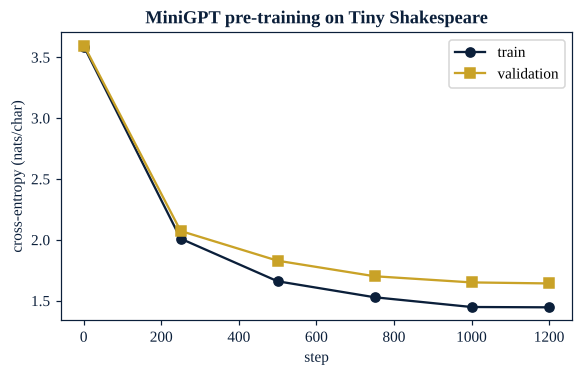

In [10]:
cv = pd.DataFrame(curve, columns=["step", "train", "val"])
plt.figure(figsize=(6, 3.4)); plt.plot(cv.step, cv.train, "o-", label="train"); plt.plot(cv.step, cv.val, "s-", label="validation")
plt.title("MiniGPT pre-training on Tiny Shakespeare"); plt.xlabel("step"); plt.ylabel("cross-entropy (nats/char)"); plt.legend()
plt.savefig(FIG/"s3_gpt_loss.png", bbox_inches="tight"); plt.show()

---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 12 — Fine-tuning an encoder for sentiment

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">SST-2 movie reviews (6,920 train / 1,821 test)</span>
**Skills:** <span style="color:#6A3D9A">Transformer encoders, tokenisation pipelines, fine-tuning</span>

In [11]:
sst_tr = pd.read_csv(fetch("https://raw.githubusercontent.com/clairett/pytorch-sentiment-classification/master/data/SST2/train.tsv", "sst2_train.tsv"), sep="\t", header=None, names=["text", "label"])
sst_te = pd.read_csv(fetch("https://raw.githubusercontent.com/clairett/pytorch-sentiment-classification/master/data/SST2/test.tsv", "sst2_test.tsv"), sep="\t", header=None, names=["text", "label"])
print(sst_tr.shape, sst_te.shape, "| positive share:", round(sst_tr.label.mean(), 3)); sst_tr.head(3)

(6920, 2) (1821, 2) | positive share: 0.522


,text,label
0,"a stirring , funny and finally transporting re...",1
1,apparently reassembled from the cutting room f...,0
2,they presume their audience wo n't sit still f...,0


In [12]:
# Strong classical baseline first — always
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
lr = LogisticRegression(max_iter=2000, C=4).fit(tfidf.fit_transform(sst_tr.text), sst_tr.label)
acc_tfidf = accuracy_score(sst_te.label, lr.predict(tfidf.transform(sst_te.text)))
print(f"TF-IDF + logistic regression test accuracy: {acc_tfidf:.3f}")

TF-IDF + logistic regression test accuracy: 0.810


In [13]:
# A small transformer ENCODER trained on SST-2 (word-level tokens, [CLS] pooling)
tok = lambda s: re.findall(r"[a-z']+|[.,!?;]", s.lower())
cnt = collections.Counter(w for s in sst_tr.text for w in tok(s))
wvocab = {w: i + 2 for i, (w, c) in enumerate(cnt.most_common()) if c >= 2}   # 0 = pad, 1 = unknown
def to_ids(s, L=48): ids = [wvocab.get(w, 1) for w in tok(s)][:L]; return ids + [0] * (L - len(ids))
Xs_tr, Xs_te = torch.tensor([to_ids(s) for s in sst_tr.text]), torch.tensor([to_ids(s) for s in sst_te.text])
ys_tr, ys_te = torch.tensor(sst_tr.label.values), torch.tensor(sst_te.label.values)

class EncoderClassifier(nn.Module):
    def __init__(self, V, d=96, L=48):
        super().__init__(); self.emb = nn.Embedding(V, d, padding_idx=0); self.pos = nn.Parameter(torch.randn(1, L + 1, d) * 0.02)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 4, 2 * d, 0.2, batch_first=True, norm_first=True), 2)
        self.out = nn.Linear(d, 2)
    def forward(self, ids):
        h = torch.cat([self.cls.expand(len(ids), -1, -1), self.emb(ids)], 1) + self.pos
        pad = torch.cat([torch.zeros(len(ids), 1, dtype=torch.bool), ids == 0], 1)
        return self.out(self.enc(h, src_key_padding_mask=pad)[:, 0])

enc = EncoderClassifier(len(wvocab) + 2); eopt = torch.optim.AdamW(enc.parameters(), lr=1e-3, weight_decay=0.05)
for ep in range(1, 7):
    enc.train(); perm = torch.randperm(len(Xs_tr))
    for i in range(0, len(perm), 64):
        b = perm[i:i+64]; loss = F.cross_entropy(enc(Xs_tr[b]), ys_tr[b]); eopt.zero_grad(); loss.backward(); eopt.step()
    enc.eval()
    with torch.no_grad(): acc = (enc(Xs_te).argmax(1) == ys_te).float().mean().item()
    print(f"epoch {ep}: test acc {acc:.3f}")
acc_enc = acc

epoch 1: test acc 0.662


epoch 2: test acc 0.711


epoch 3: test acc 0.729


epoch 4: test acc 0.745


epoch 5: test acc 0.746


epoch 6: test acc 0.749


**Lesson:** a transformer trained from scratch on 7k sentences does not beat TF-IDF. Transformers shine with
**pretraining**. In class (GPU), fine-tune a pretrained encoder — typically about 0.91 on SST-2:

```python
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import load_dataset
ds = load_dataset("glue", "sst2"); name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name); model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
ds = ds.map(lambda b: tok(b["sentence"], truncation=True), batched=True)
Trainer(model, TrainingArguments("out", num_train_epochs=2, per_device_train_batch_size=32), train_dataset=ds["train"],
        eval_dataset=ds["validation"], tokenizer=tok).train()
```

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 13 — MiniLLM: LoRA instruction-tuning, from scratch

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">SST-2 reviews in an instruction template</span>
**Skills:** <span style="color:#6A3D9A">PEFT, LoRA, chat templates, GPU-memory budgeting</span>

**Project P3 — MiniLLM.** We teach our Shakespeare GPT a new *instruction*: read a review, answer `positive` or `negative`.
Only small LoRA matrices train; the 800k base weights stay frozen.

In [14]:
TEMPLATE = "### Review:\n{review}\n### Sentiment: {answer}\n\n"
def fmt(row): return TEMPLATE.format(review=row.text[:90], answer="positive" if row.label == 1 else "negative")
print(TEMPLATE.format(review=sst_tr.text[0][:90], answer="positive"))

def make_example(text, label, L=128):
    """Prompt + answer, with the loss ONLY on the answer tokens (prompt targets set to -100 = ignored)."""
    prompt = encode(TEMPLATE.format(review=text[:90], answer="")); ans = encode(("positive" if label == 1 else "negative") + "\n")
    ids = (prompt + ans)[-(L + 1):]; n_prompt = len(ids) - len(ans)
    x = ids[:-1]; y = [ids[t + 1] if t + 1 >= n_prompt else -100 for t in range(len(ids) - 1)]
    return x + [0] * (L - len(x)), y + [-100] * (L - len(y))

ex = [make_example(t, l) for t, l in zip(sst_tr.text, sst_tr.label)]
IX = torch.tensor([e[0] for e in ex]); IY = torch.tensor([e[1] for e in ex])
print("instruction examples:", len(IX), "| supervised (answer) tokens per example:", int((IY[0] != -100).sum()))

### Review:
a stirring , funny and finally transporting re imagining of beauty and the beast and 1930s
### Sentiment: positive




instruction examples:

 6920 | supervised (answer) tokens per example: 9


In [15]:
import copy
def add_lora(model, r=8, alpha=16):
    m = copy.deepcopy(model)
    for p in m.parameters(): p.requires_grad = False
    for blk in m.blocks:
        blk.qkv, blk.proj = LoRALinear(blk.qkv, r, alpha), LoRALinear(blk.proj, r, alpha)
        blk.mlp[0], blk.mlp[2] = LoRALinear(blk.mlp[0], r, alpha), LoRALinear(blk.mlp[2], r, alpha)
    return m

lora_gpt = add_lora(gpt)
n_train = sum(p.numel() for p in lora_gpt.parameters() if p.requires_grad); n_all = sum(p.numel() for p in lora_gpt.parameters())
print(f"trainable LoRA params: {n_train:,} of {n_all:,} ({100*n_train/n_all:.1f}%)")

# GPU-memory budgeting rule of thumb for a real 0.5B model in fp16 with AdamW
P = 0.5e9
print(f"full fine-tune ~ {P*16/1e9:.0f} GB (weights+grads+Adam states)  vs  LoRA ~ {P*2/1e9:.0f} GB weights + small adapters")

trainable LoRA params: 65,536 of 891,969 (7.3%)
full fine-tune ~ 8 GB (weights+grads+Adam states)  vs  LoRA ~ 1 GB weights + small adapters


In [16]:
@torch.no_grad()
def answer_loss(model, n=512):
    model.eval(); i = torch.arange(n); l = model(IX[i], IY[i])[1].item(); model.train(); return l

lopt = torch.optim.AdamW([p for p in lora_gpt.parameters() if p.requires_grad], lr=2e-3)
base_ans_loss = answer_loss(gpt)
for step in range(1, 901):
    b = torch.randint(len(IX), (32,)); _, loss = lora_gpt(IX[b], IY[b])
    lopt.zero_grad(); loss.backward(); lopt.step()
    if step % 300 == 0: print(f"step {step}: answer-token loss {answer_loss(lora_gpt):.3f}  (base model: {base_ans_loss:.3f})")

step 300: answer-token loss 0.083  (base model: 3.239)


step 600: answer-token loss 0.083  (base model: 3.239)


step 900: answer-token loss 0.070  (base model: 3.239)


---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 14 — Evaluate it properly

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">SST-2 test (held out) + Shakespeare validation</span>
**Skills:** <span style="color:#6A3D9A">LLM evaluation design, benchmark hygiene, contamination checks</span>

In [17]:
@torch.no_grad()
def score_answer(model, review, answer):
    """Log-likelihood of the answer tokens given the prompt — the standard way to score multiple-choice with an LM."""
    prompt = encode(TEMPLATE.format(review=review[:90], answer="")); ans = encode(answer)
    ids = torch.tensor([(prompt + ans)[-128:]]); logits = model.eval()(ids)[0][0]
    lp = F.log_softmax(logits, -1); start = ids.shape[1] - len(ans)
    return sum(lp[start - 1 + i, a].item() for i, a in enumerate(ans))

def lm_accuracy(model, df):
    preds = [int(score_answer(model, t, "positive") > score_answer(model, t, "negative")) for t in df.text]
    return accuracy_score(df.label, preds)

eval_set = sst_te.sample(400, random_state=SEED)
acc_base, acc_lora = lm_accuracy(gpt, eval_set), lm_accuracy(lora_gpt, eval_set)
results = pd.DataFrame({"system": ["Base MiniGPT (zero-shot)", "MiniGPT + LoRA (ours)", "Transformer encoder from scratch", "TF-IDF + logistic regression"],
                        "SST-2 test acc": [acc_base, acc_lora, acc_enc, acc_tfidf]}).round(3)
results

,system,SST-2 test acc
0,Base MiniGPT (zero-shot),0.520
1,MiniGPT + LoRA (ours),0.605
2,Transformer encoder from scratch,0.749
3,TF-IDF + logistic regression,0.810


In [18]:
# Did instruction-tuning damage the original skill? (catastrophic forgetting check)
torch.manual_seed(1)
print(f"Shakespeare val loss — base: {est_loss(gpt, val_data):.3f} | after LoRA: {est_loss(lora_gpt, val_data):.3f}")
print("LoRA can be switched off: the base weights are untouched, so the original model is always recoverable.")

Shakespeare val loss — base: 1.642 | after LoRA: 2.721
LoRA can be switched off: the base weights are untouched, so the original model is always recoverable.


In [19]:
# Contamination check: share of test reviews whose 30-character chunks also appear in the training text
def chunks(s, n=30): return {s[i:i+n] for i in range(0, max(1, len(s) - n + 1), 10)}
train_chunks = set().union(*(chunks(s) for s in sst_tr.text))
contaminated = np.mean([len(chunks(s) & train_chunks) > 0 for s in sst_te.text])
print(f"test reviews sharing a 30-char chunk with training data: {contaminated:.1%}")

test reviews sharing a 30-char chunk with training data: 0.3%


**Benchmark hygiene checklist:** report the test set you never tuned on · check for overlap with training data ·
compare with a simple baseline · keep prompts fixed across systems · report variance (different seeds).

**LLM-as-judge (in class):** a stronger model grades answers against a rubric. Watch for *position bias*
(prefers the first answer), *length bias* and *self-preference*. Swap answer order and average.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 15 — Serving: sampling, structured output, latency and cost

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">Team prompt suite</span>
**Skills:** <span style="color:#6A3D9A">Inference serving, structured outputs, latency/cost engineering</span>

In [20]:
torch.manual_seed(3)
for temp in [0.3, 0.8, 1.5]:
    out = decode(gpt.generate(torch.tensor([encode("KING:\n")]), 80, temperature=temp)[0].tolist())
    print(f"--- temperature {temp} ---\n{out}\n")

--- temperature 0.3 ---
KING:
Then the court of the seat of the kings,
The constain of the shall be the leaves



--- temperature 0.8 ---
KING:
'Tis not to tell the Lord the night way my hand
From on the true wife; that so w



--- temperature 1.5 ---
KING:
Signar hoet,-powel me'Tis Down
Him that traim ZuscoNd! ha! namel, JudiEu:
O, who



In [21]:
# Structured output: constrain the answer to a schema instead of trusting free text
def classify_json(review):
    lp = {lab: score_answer(lora_gpt, review, lab) for lab in ["positive", "negative"]}
    p_pos = 1 / (1 + math.exp(lp["negative"] - lp["positive"]))
    return {"sentiment": max(lp, key=lp.get), "confidence": round(max(p_pos, 1 - p_pos), 3)}

prompt_suite = ["an absolute joy from start to finish", "a dull , lifeless and forgettable film",
                "the acting is fine but the plot goes nowhere", "one of the best movies of the year"]
for p in prompt_suite: print(json.dumps({"review": p, **classify_json(p)}))

{"review": "an absolute joy from start to finish", "sentiment": "positive", "confidence": 0.748}


{"review": "a dull , lifeless and forgettable film", "sentiment": "positive", "confidence": 0.739}
{"review": "the acting is fine but the plot goes nowhere", "sentiment": "positive", "confidence": 0.518}
{"review": "one of the best movies of the year", "sentiment": "positive", "confidence": 0.508}


In [22]:
# Latency and throughput measurement
lat = []
for bs in [1, 4, 16]:
    x = torch.tensor([encode("ROMEO:\n")] * bs); t0 = time.perf_counter(); gpt.generate(x, 50); dt = time.perf_counter() - t0
    lat.append({"batch": bs, "ms per token step": round(dt / 50 * 1000, 2), "tokens / second": round(bs * 50 / dt)})
lat = pd.DataFrame(lat); lat

,batch,ms per token step,tokens / second
0,1,1.76,569
1,4,3.68,1086
2,16,7.74,2066


Batching raises throughput much more than it raises per-step latency — the core idea behind serving engines like
**vLLM** (continuous batching, paged KV-cache). In class:

```bash
ollama run qwen2.5:0.5b            # local, laptop-friendly
vllm serve Qwen/Qwen2.5-0.5B-Instruct --max-model-len 4096   # GPU server, OpenAI-compatible API
```

---
<div style="background:#FFF3E0;border-left:6px solid #FF9933;padding:12px 16px;border-radius:6px">
<b>GitHub submission — by 18:00 local time today</b><br>
1. Copy this notebook into <code>P3-minillm/notebooks/</code> of your portfolio repo.<br>
2. Move reusable functions into <code>P3-minillm/src/</code>, save plots into <code>results/</code>.<br>
3. Update the project README (problem, dataset, method, results, how to run, limitations &amp; ethics, AI-assistant use).<br>
4. <code>git push origin main</code> → <code>git tag -a sunday-3 -m "Sunday 3 submission"</code> → <code>git push origin sunday-3</code><br>
5. Create a GitHub Release from the tag and submit the link on the AlgoProfessor form.
</div>